# Part 2 - Rule-based event detection (L1-L4)
**Notebook 2 of 4.** It reads only the original logs and the dictionary (not Part 1's table):
steps and stops are measured on the **original timestamps**, so the 85 ms grid is not needed here.

A **step** is one ON-period of an output signal (a motor, a pusher, a valve).
A **stop** is a period where the safety light curtain is interrupted (Siemens `A201.0` = 0)
or the operator screen is paused (`Visual.start` = 0).

"Exact" here means exact to the recorded timestamps: each log still only samples its signals
(every 76 or 93 ms), so a step's real start or end can lie up to one sampling interval away
from the recorded one.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '../data/raw/'       # original files (never changed)
OUT_DIR = '../data/processed'   # the joined table
RES_DIR = '../results'          # result tables
FIG_DIR = '../results/figures'  # charts
for folder in (OUT_DIR, RES_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

GRID_MS = 85        # time step of the joined table
SLOW_FACTOR = 1.25  # a step is "slow" if it takes at least 25 % longer than its normal time ...
MIN_EXTRA_S = 2.0   # ... and at least 2 seconds longer (own assumption, agreed in the team)
MIN_REPEATS = 5     # a normal time is only calculated for steps that repeat at least 5 times

BLUE, ORANGE, PURPLE, GREY = '#2f7fb3', '#c9701a', '#8a5fc0', '#c5ccd3'
pd.set_option('display.width', 200, 'display.max_columns', 30)

In [2]:
def load_log(file_name):
    """Read one PLC log as text, then give each column its real type."""
    df = pd.read_csv(DATA_DIR + file_name, sep=';', dtype=str)
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]  # empty column from the trailing ';'
    df = df.rename(columns={'timestamp': 'ts_ms'})
    df['ts_ms'] = df['ts_ms'].astype('int64')  # Unix time in milliseconds
    for col in df.columns[1:]:
        values = df[col]
        if set(values.dropna().unique()) <= {'True', 'False'}:
            df[col] = values.map({'True': 1.0, 'False': 0.0})
        else:
            df[col] = pd.to_numeric(values.str.replace(',', '.'), errors='coerce')
    return df


beck = load_log('Beispieldatensatz_Beckhoff_SPS.csv')
sie = load_log('Beispieldatensatz_Siemens_S7_SPS.csv')
print('Beckhoff:', beck.shape, '| Siemens:', sie.shape)

rows_before = len(sie)
sie = sie.dropna().reset_index(drop=True)
print('Siemens rows dropped because of empty cells:', rows_before - len(sie))
print('Beckhoff rows with empty cells:', int(beck.isna().any(axis=1).sum()))

T0 = min(beck['ts_ms'].min(), sie['ts_ms'].min())    # common time zero (Unix ms)
T_END = min(beck['ts_ms'].max(), sie['ts_ms'].max())
for df in (beck, sie):
    df['ms'] = df['ts_ms'] - T0     # milliseconds from time zero
    df['src_ms'] = df['ms']         # this row's own time, kept as "source"

Beckhoff: (5197, 54) | Siemens: (6283, 143)
Siemens rows dropped because of empty cells: 1
Beckhoff rows with empty cells: 0


In [3]:
def pulses(df, col, level=1):
    """All complete periods where df[col] equals `level`.

    Returns (start, end) pairs in milliseconds from time zero,
    measured on the log's own timestamps.
    """
    x = (df[col] == level).astype(int)
    change = x.diff()
    starts = df.loc[change[change == 1].index, 'ms']
    ends = df.loc[change[change == -1].index, 'ms']
    result = []
    for start in starts:
        later_ends = ends[ends > start]
        if len(later_ends) > 0:
            result.append((start, later_ends.iloc[0]))
    return result


def overlap(a0, a1, b0, b1):
    """Seconds that the periods a0-a1 and b0-b1 have in common."""
    return max(0.0, min(a1, b1) - max(a0, b0))

# --- stops ---
stop_rows = []
for start, end in pulses(sie, 'A201.0', level=0):
    stop_rows.append(('light curtain', start / 1000, end / 1000))
for start, end in pulses(beck, 'Visual.start', level=0):
    stop_rows.append(('operator screen pause', start / 1000, end / 1000))
stops = pd.DataFrame(stop_rows, columns=['cause', 'start_s', 'end_s'])
stops = stops.sort_values('start_s').reset_index(drop=True)
stops['dur_s'] = stops['end_s'] - stops['start_s']
stops.round(3).to_csv(RES_DIR + '/stops.csv', index=False)
stops.round(2)

,cause,start_s,end_s,dur_s
0,light curtain,255.40,264.29,8.90
1,light curtain,390.06,400.44,10.38
2,light curtain,453.14,460.74,7.60
3,operator screen pause,468.55,473.45,4.90


In [4]:
# --- steps: every ON-period of every output signal ---
# Outputs that are NOT process steps: data sent to Beckhoff, compressors,
# a blinking light, the oven-door command (they stay on for long = states).
NOT_STEPS = ['A200', 'A201', 'A6.', 'A0.1', 'A1.5', 'A1.6', 'A4.1']
# The Beckhoff log has every output twice (short and long name); skip the long copies.
LONG_COPIES = ('_horizontal_', '_vertical_', '_cantilever_')

signal_sources = []  # (display name, log table, column in that table)
for col in sie.columns:
    if col.startswith('A') and not col.startswith(tuple(NOT_STEPS)):
        signal_sources.append(('SIE_' + col, sie, col))
for col in beck.columns:
    if '.Q' in col and not any(w in col for w in LONG_COPIES):
        signal_sources.append(('BECK_' + col, beck, col))

rows = []
for label, df, col in signal_sources:
    for start, end in pulses(df, col):
        rows.append((label, start / 1000, end / 1000, (end - start) / 1000))
steps = pd.DataFrame(rows, columns=['signal', 'start_s', 'end_s', 'dur_s'])

# normal time per signal = median, only for signals that repeat often enough
normal = steps.groupby('signal')['dur_s'].agg(['count', 'median'])
normal = normal[(normal['count'] >= MIN_REPEATS) & (normal['median'] >= 0.25)]
steps = steps.merge(normal['median'].rename('normal_s'),
                    left_on='signal', right_index=True)
steps['extra_s'] = steps['dur_s'] - steps['normal_s']
steps['slow'] = ((steps['dur_s'] >= SLOW_FACTOR * steps['normal_s'])
                 & (steps['extra_s'] >= MIN_EXTRA_S))

print('output signals:', len(signal_sources),
      '| signals with a normal time:', len(normal),
      '| steps measured:', len(steps), '| slow steps:', int(steps['slow'].sum()))

output signals: 32 | signals with a normal time: 28 | steps measured: 488 | slow steps: 14


### L1: Some machine steps take longer than usual
For every slow step: how much longer than normal, and is it slow by itself or only paused by a stop?
The station name comes from the signal dictionary.

In [5]:
import openpyxl

wb = openpyxl.load_workbook(DATA_DIR + 'Variablenerkl_rung.xlsx')
SIE_DICT = {r[0]: (r[3], r[4], r[2])
            for r in wb['Siemens'].iter_rows(min_row=2, values_only=True) if r[0]}
BEC_DICT = {r[0]: r[1]
            for r in wb['Beckhoff'].iter_rows(min_row=2, values_only=True) if r[0]}


def dictionary_station(signal):
    name = signal.split('_', 1)[1]  # remove the SIE_ / BECK_ prefix
    if signal.startswith('SIE_'):
        return SIE_DICT.get(name, ('?', '', ''))[0]
    return BEC_DICT.get(name, '?')


def dictionary_text(signal):
    name = signal.split('_', 1)[1]
    if signal.startswith('SIE_'):
        return SIE_DICT.get(name, ('', '', ''))[2]
    return name


slow = steps[steps['slow']].copy()
slow['stop_in_step_s'] = [sum(overlap(r.start_s, r.end_s, st.start_s, st.end_s)
                              for st in stops.itertuples())
                          for r in slow.itertuples()]
slow['cause'] = np.where(slow['stop_in_step_s'] >= 0.5 * slow['extra_s'],
                         'paused by a stop', 'slow by itself')
slow['station'] = slow['signal'].map(dictionary_station)
slow['dictionary text'] = slow['signal'].map(dictionary_text)
slow['times_normal'] = slow['dur_s'] / slow['normal_s']
slow = slow.sort_values('start_s')
slow[['signal', 'station', 'dictionary text', 'start_s', 'dur_s',
      'normal_s', 'extra_s', 'times_normal', 'stop_in_step_s', 'cause']].round(2)

,signal,station,dictionary text,start_s,dur_s,normal_s,extra_s,times_normal,stop_in_step_s,cause
468,BECK_VG.Q7_compressorON,Robot,VG.Q7_compressorON,74.24,9.79,7.77,2.02,1.26,0.00,slow by itself
166,BECK_WH.Q4_horBelt,Warehouse,WH.Q4_horBelt,109.01,4.47,1.73,2.74,2.58,0.00,slow by itself
156,BECK_WH.Q3_horRack,Warehouse,WH.Q3_horRack,252.42,13.61,3.10,10.50,4.38,8.90,paused by a stop
118,SIE_A1.7,Drilling station,Suction on/off (output),254.15,18.02,9.22,8.80,1.95,8.90,paused by a stop
171,BECK_WH.Q4_horBelt,Warehouse,WH.Q4_horBelt,283.44,4.36,1.73,2.63,2.52,0.00,slow by itself
285,BECK_WH.Q1_beltForward,Warehouse,WH.Q1_beltForward,291.28,7.80,0.86,6.94,9.11,0.00,slow by itself
294,BECK_WH.Q2_beltBackward,Warehouse,WH.Q2_beltBackward,314.84,6.79,0.57,6.22,11.92,0.00,slow by itself
286,BECK_WH.Q1_beltForward,Warehouse,WH.Q1_beltForward,350.80,9.62,0.86,8.77,11.24,0.00,slow by itself
65,SIE_A0.7,Drilling station,conveyor on,363.10,7.99,5.77,2.21,1.38,0.00,slow by itself
75,SIE_A1.0,Drilling station,drill on (output),385.07,5.07,0.99,4.08,5.13,0.08,slow by itself


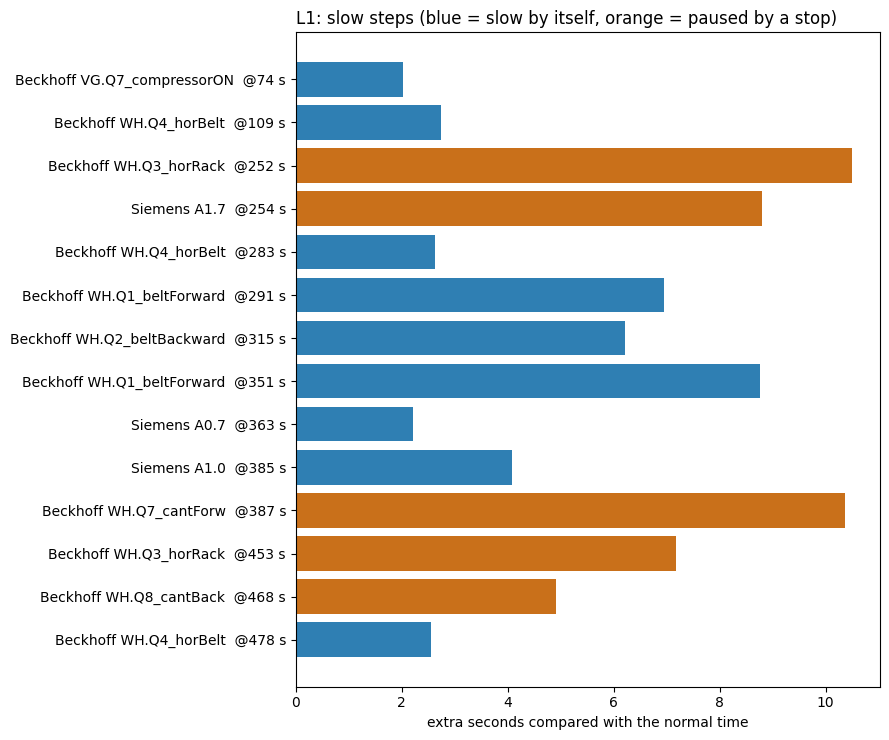

In [6]:
# chart: extra time of every slow step
fig, ax = plt.subplots(figsize=(9, 0.45 * len(slow) + 1.2))
labels = [s.replace('SIE_', 'Siemens ').replace('BECK_', 'Beckhoff ') + '  @%.0f s' % t
          for s, t in zip(slow['signal'], slow['start_s'])]
colors = [ORANGE if c == 'paused by a stop' else BLUE for c in slow['cause']]
ax.barh(labels[::-1], slow['extra_s'][::-1], color=colors[::-1])
ax.set_xlabel('extra seconds compared with the normal time')
ax.set_title('L1: slow steps (blue = slow by itself, orange = paused by a stop)',
             loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/L1_slow_steps.png', dpi=150)
plt.show()

### Cycles (needed for L2 to L4)
One **cycle** = time between two starts of the warehouse belt (`WH.Q1_beltForward`), i.e. one pallet.
The normal cycle time is the median of the cycles without a stop or slow step
(the first cycle is the start-up and is skipped).

belt starts: 9 | complete cycles: 8 | normal cycle time: 53.4 s


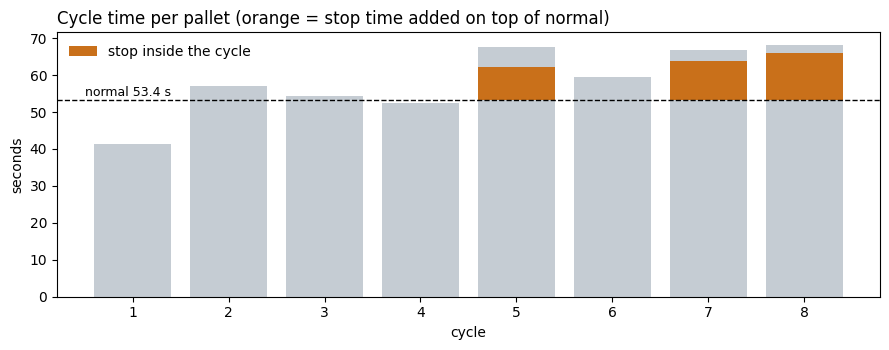

,cycle,start_s,end_s,dur_s,stop_s,slow_steps,clean,extra_s
0,1,18.6,60.1,41.5,0.0,0,False,-11.9
1,2,60.1,117.0,57.0,0.0,2,False,3.6
2,3,117.0,171.2,54.2,0.0,0,True,0.9
3,4,171.2,223.7,52.5,0.0,0,True,-0.9
4,5,223.7,291.3,67.5,8.9,3,False,14.2
5,6,291.3,350.8,59.5,0.0,2,False,6.2
6,7,350.8,417.7,66.9,10.4,4,False,13.5
7,8,417.7,485.9,68.2,12.5,3,False,14.8


In [7]:
belt_starts = [start / 1000 for start, end in pulses(beck, 'WH.Q1_beltForward')]
cycle_rows = []
for i in range(len(belt_starts) - 1):
    c0, c1 = belt_starts[i], belt_starts[i + 1]
    stop_s = sum(overlap(c0, c1, st.start_s, st.end_s) for st in stops.itertuples())
    slow_n = int(((slow['start_s'] >= c0) & (slow['start_s'] < c1)).sum())
    cycle_rows.append((i + 1, c0, c1, c1 - c0, stop_s, slow_n))
cycles = pd.DataFrame(cycle_rows,
                      columns=['cycle', 'start_s', 'end_s', 'dur_s', 'stop_s', 'slow_steps'])
cycles['clean'] = ((cycles['stop_s'] == 0) & (cycles['slow_steps'] == 0)
                   & (cycles['cycle'] > 1))
CYCLE_NORMAL = cycles.loc[cycles['clean'], 'dur_s'].median()
cycles['extra_s'] = cycles['dur_s'] - CYCLE_NORMAL
print('belt starts:', len(belt_starts), '| complete cycles:', len(cycles),
      '| normal cycle time: %.1f s' % CYCLE_NORMAL)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(cycles['cycle'], cycles['dur_s'], color=GREY)
ax.bar(cycles['cycle'], cycles['stop_s'], bottom=CYCLE_NORMAL,
       color=ORANGE, label='stop inside the cycle')
ax.axhline(CYCLE_NORMAL, color='black', lw=1, ls='--')
ax.text(0.5, CYCLE_NORMAL + 1, 'normal %.1f s' % CYCLE_NORMAL, fontsize=9)
ax.set_xlabel('cycle')
ax.set_ylabel('seconds')
ax.legend(frameon=False)
ax.set_title('Cycle time per pallet (orange = stop time added on top of normal)',
             loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/cycles.png', dpi=150)
plt.show()
cycles.round(1).to_csv(RES_DIR + '/cycles.csv', index=False)
cycles.round(1)

### L2: The robot's transfers cause waiting
Per cycle: time from the belt start until the robot grips the block (`VG.Q7_compressorON` on),
and how long the robot then needs until it releases (`VG.Q7` off).
The dictionary has no explicit "ready" or "transfer finished" signal, so these two times
are the best available measure.

Note: the robot is logged by Beckhoff and the oven by Siemens. Comparing the two assumes
the PLC clocks agree, which is not verified (see Part 1).

oven starts under 2 s after a robot release in 6 of 9 cases; 14 s or more in 3 cases
normal belt-start-to-grip: 1.44 s | normal grip-to-release: 6.65 s


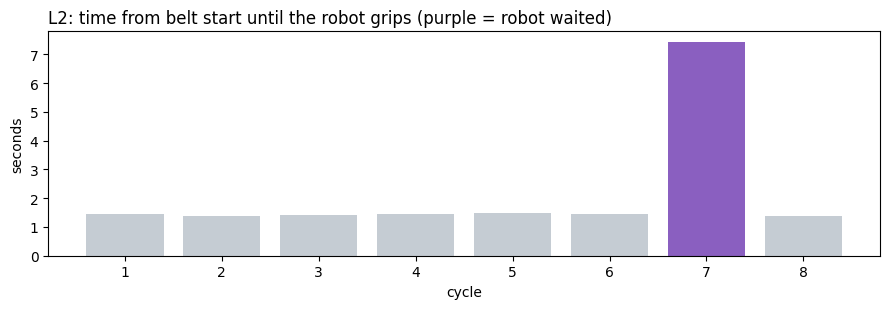

                                 0       1       2       3       4       5       6       7       8
oven_in_s                    28.42  100.41  125.59  179.68  246.17  299.71  341.13  365.12  427.45
seconds_after_robot_release   1.70   16.38    0.50    0.38   14.32    0.26   26.83    0.25    1.76


,cycle,belt_start_to_grip_s,grip_to_release_s,extra_wait_s,robot_waited
0,1,1.46,6.69,0.02,False
1,2,1.39,6.70,-0.06,False
2,3,1.42,6.66,-0.03,False
3,4,1.43,6.62,-0.01,False
4,5,1.50,6.63,0.05,False
5,6,1.45,6.72,0.01,False
6,7,7.43,6.64,5.98,True
7,8,1.38,6.62,-0.07,False


In [8]:
grips = pulses(beck, 'VG.Q7_compressorON')  # (grip, release) pairs
rows = []
for r in cycles.itertuples():
    first_grip = [(g / 1000, e / 1000) for g, e in grips
                  if r.start_s <= g / 1000 < r.end_s]
    if first_grip:
        g, e = first_grip[0]
        rows.append((r.cycle, g - r.start_s, e - g))
robot = pd.DataFrame(rows, columns=['cycle', 'belt_start_to_grip_s', 'grip_to_release_s'])
WAIT_NORMAL = robot['belt_start_to_grip_s'].median()
robot['extra_wait_s'] = robot['belt_start_to_grip_s'] - WAIT_NORMAL
robot['robot_waited'] = robot['extra_wait_s'] >= 1.0

# robot -> oven: how long after the robot's last release does the oven move in (Siemens A1.1)?
releases = [end / 1000 for start, end in grips]
oven_rows = []
for start, end in pulses(sie, 'A1.1'):
    last_release = max(r for r in releases if r <= start / 1000 + 0.1)
    oven_rows.append((start / 1000, start / 1000 - last_release))
oven_in = pd.DataFrame(oven_rows, columns=['oven_in_s', 'seconds_after_robot_release'])
print('oven starts under 2 s after a robot release in %d of %d cases; '
      '14 s or more in %d cases' % (
          (oven_in['seconds_after_robot_release'] < 2).sum(), len(oven_in),
          (oven_in['seconds_after_robot_release'] >= 14).sum()))
print('normal belt-start-to-grip: %.2f s | normal grip-to-release: %.2f s' % (
    WAIT_NORMAL, robot['grip_to_release_s'].median()))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(robot['cycle'], robot['belt_start_to_grip_s'],
       color=[PURPLE if w else GREY for w in robot['robot_waited']])
ax.set_xlabel('cycle')
ax.set_ylabel('seconds')
ax.set_title('L2: time from belt start until the robot grips (purple = robot waited)',
             loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/L2_robot_wait.png', dpi=150)
plt.show()
robot.round(3).to_csv(RES_DIR + '/robot_waits.csv', index=False)
oven_in.round(3).to_csv(RES_DIR + '/oven_after_release.csv', index=False)
print(oven_in.round(2).T.to_string())
robot.round(2)

### L3: Short pauses increase the time between completed parts
A **completed part** = one of the colour pushers (`A0.2` white, `A0.3` red, `A0.4` blue)
fires at the sorting station. For every gap between two completions: how many seconds
of stop lie inside it?

completed parts: 10 | median gap between parts: 45.7 s


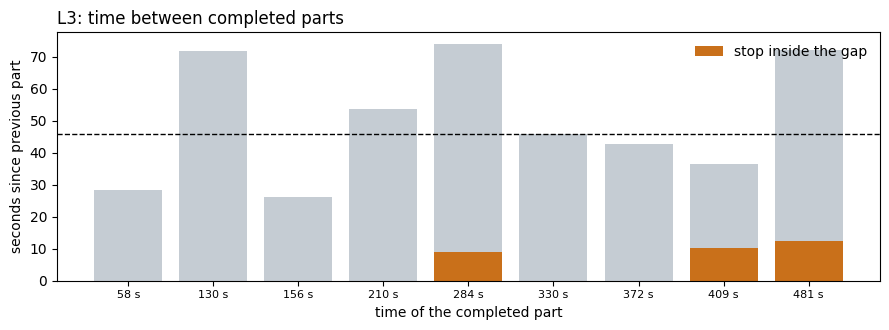

,time_s,colour,gap_s,stop_in_gap_s,oven_delay_in_gap_s,long_gap
0,29.9,blue,NaN,0.0,0.0,False
1,58.3,red,28.4,0.0,0.0,False
2,130.0,red,71.7,0.0,16.4,True
3,156.1,blue,26.1,0.0,0.0,False
4,209.9,blue,53.8,0.0,0.4,False
5,283.9,white,73.9,8.9,14.3,True
6,329.6,red,45.7,0.0,0.3,False
7,372.3,white,42.7,0.0,26.8,False
8,408.7,white,36.4,10.4,0.0,False
9,480.7,white,72.0,12.5,1.8,True


In [9]:
done = []
for name, col in [('white', 'A0.2'), ('red', 'A0.3'), ('blue', 'A0.4')]:
    for start, end in pulses(sie, col):
        done.append((start / 1000, name))
done = pd.DataFrame(sorted(done), columns=['time_s', 'colour'])
done['gap_s'] = done['time_s'].diff()
done['stop_in_gap_s'] = [sum(overlap(a, b, st.start_s, st.end_s)
                             for st in stops.itertuples())
                         for a, b in zip(done['time_s'].shift(1), done['time_s'])]
# longest robot-release -> oven-start delay (from L2) inside the gap
done['oven_delay_in_gap_s'] = [
    max([d for t, d in zip(oven_in['oven_in_s'],
                           oven_in['seconds_after_robot_release'])
         if a < t <= b] + [0])
    for a, b in zip(done['time_s'].shift(1), done['time_s'])]
GAP_NORMAL = done['gap_s'].median()
done['long_gap'] = done['gap_s'] >= SLOW_FACTOR * GAP_NORMAL
print('completed parts:', len(done), '| median gap between parts: %.1f s' % GAP_NORMAL)

g = done.dropna()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(len(g)), g['gap_s'], color=GREY)
ax.bar(range(len(g)), g['stop_in_gap_s'], color=ORANGE, label='stop inside the gap')
ax.axhline(GAP_NORMAL, color='black', lw=1, ls='--')
ax.set_xticks(range(len(g)))
ax.set_xticklabels(['%.0f s' % t for t in g['time_s']], fontsize=8)
ax.set_xlabel('time of the completed part')
ax.set_ylabel('seconds since previous part')
ax.legend(frameon=False)
ax.set_title('L3: time between completed parts', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/L3_completed_parts.png', dpi=150)
plt.show()
done.round(3).to_csv(RES_DIR + '/completed_parts.csv', index=False)
done.round(1)

### L4: One station causes more delay than the others
Lost time per equipment. The station name comes from the dictionary (checked in the L1 table).
Light-curtain and operator-screen stops hit every station at once, so they are shown separately.

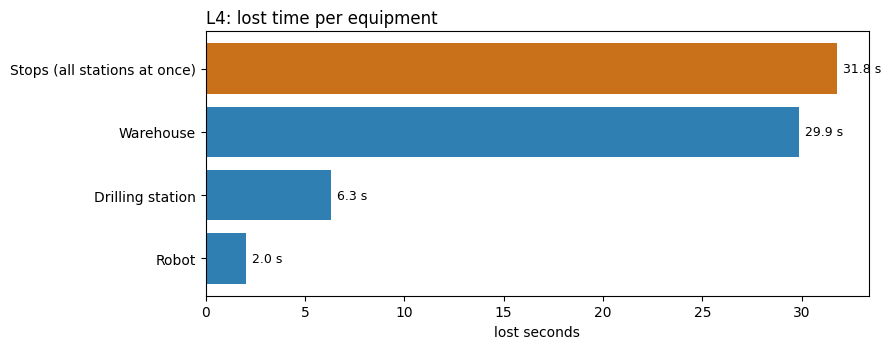

Steps stretched only because a stop paused them (already counted as stop time): 41.8 s


,lost_s
Robot,2.0
Drilling station,6.3
Warehouse,29.9
Stops (all stations at once),31.8


In [10]:
by_station = (slow[slow['cause'] == 'slow by itself']
              .groupby('station')['extra_s'].sum().sort_values(ascending=False))
paused = slow[slow['cause'] == 'paused by a stop']['extra_s'].sum()
loss = by_station.to_dict()
loss['Stops (all stations at once)'] = stops['dur_s'].sum()
loss = pd.Series(loss).sort_values()

fig, ax = plt.subplots(figsize=(9, 0.6 * len(loss) + 1.2))
colors = [ORANGE if 'Stops' in n else BLUE for n in loss.index]
ax.barh(loss.index, loss.values, color=colors)
for y, v in enumerate(loss.values):
    ax.text(v + 0.3, y, '%.1f s' % v, va='center', fontsize=9)
ax.set_xlabel('lost seconds')
ax.set_title('L4: lost time per equipment', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR + '/L4_loss_per_equipment.png', dpi=150)
plt.show()
print('Steps stretched only because a stop paused them '
      '(already counted as stop time): %.1f s' % paused)
loss.round(2).to_frame('lost_s').to_csv(RES_DIR + '/loss_per_equipment.csv')
loss.round(1).to_frame('lost_s')

### Do the gaps explain anything?
Last check of this part: for every slow step, does a logging gap of the SAME PLC sit at its
start or end, large enough to fake the extra time? (The gaps themselves were found in Part 1;
they are recomputed here so this notebook stays readable on its own.)

In [11]:
def find_gaps(df, plc, min_gap_ms=300):
    """All places where one log was silent for more than `min_gap_ms`."""
    dt = df['ts_ms'].diff()
    index = dt[dt > min_gap_ms].index
    return pd.DataFrame({'plc': plc,
                         'gap_start_s': (df['ts_ms'].shift(1)[index] - T0) / 1000,
                         'gap_end_s': (df['ts_ms'][index] - T0) / 1000,
                         'gap_s': dt[index] / 1000})


gaps = pd.concat([find_gaps(beck, 'Beckhoff'), find_gaps(sie, 'Siemens')])
gaps = gaps.reset_index(drop=True)


def gap_at(time_s, plc):
    g = gaps[(gaps['plc'] == plc) & (gaps['gap_start_s'] <= time_s)
             & (time_s <= gaps['gap_end_s'])]
    return g['gap_s'].max() if len(g) else 0.0


slow['plc'] = np.where(slow['signal'].str.startswith('SIE_'), 'Siemens', 'Beckhoff')
slow['gap_at_start_s'] = [gap_at(t, p) for t, p in zip(slow['start_s'], slow['plc'])]
slow['gap_at_end_s'] = [gap_at(t, p) for t, p in zip(slow['end_s'], slow['plc'])]
slow['could_be_gap'] = (slow[['gap_at_start_s', 'gap_at_end_s']].max(axis=1)
                        >= slow['extra_s'])
print('slow steps that a logging gap could explain:', int(slow['could_be_gap'].sum()),
      'of', len(slow))
slow.round(3).to_csv(RES_DIR + '/slow_steps.csv', index=False)
print('saved: results/stops.csv, results/slow_steps.csv (+ the tables above)')
slow[['signal', 'start_s', 'end_s', 'extra_s',
      'gap_at_start_s', 'gap_at_end_s', 'could_be_gap']].round(2)

slow steps that a logging gap could explain: 0 of 14
saved: results/stops.csv, results/slow_steps.csv (+ the tables above)


,signal,start_s,end_s,extra_s,gap_at_start_s,gap_at_end_s,could_be_gap
468,BECK_VG.Q7_compressorON,74.24,84.03,2.02,0.0,0.0,False
166,BECK_WH.Q4_horBelt,109.01,113.49,2.74,0.0,0.0,False
156,BECK_WH.Q3_horRack,252.42,266.03,10.50,0.0,0.0,False
118,SIE_A1.7,254.15,272.17,8.80,0.0,0.0,False
171,BECK_WH.Q4_horBelt,283.44,287.81,2.63,0.0,0.0,False
285,BECK_WH.Q1_beltForward,291.28,299.08,6.94,0.0,0.0,False
294,BECK_WH.Q2_beltBackward,314.84,321.63,6.22,0.0,0.0,False
286,BECK_WH.Q1_beltForward,350.80,360.42,8.77,0.0,0.0,False
65,SIE_A0.7,363.10,371.09,2.21,0.0,0.0,False
75,SIE_A1.0,385.07,390.14,4.08,0.0,0.0,False


**Done.** All rule-based tables are in `results/`.
Next: `part3_clustering_model/03_clustering_model.ipynb`.